# Дополнительное задание (ЛР2). Классификация с кросс-валидацией на TensorFlow

## Введение

**Датасет:** Indian Liver Patient Dataset (indian_liver_patient.csv) — 583 пациента, 10 признаков (возраст, пол, 8 лабораторных показателей крови), целевая переменная — наличие заболевания печени.

**Цель:** освоить пайплайн обучения нейронной сети для классификации: baseline, 5-кратная стратифицированная кросс-валидация, Grid Search по скорости обучения и архитектуре, мониторинг в TensorBoard, сравнение конфигураций и честная финальная оценка.

**Задание**:

1. Загрузка и подготовка. Загрузить датасет, выполнить первичный анализ (распределение классов, пропуски, типы признаков). При необходимости выполнить предобработку: кодирование категориальных признаков, масштабирование числовых, разделение на признаки и целевую переменную. Сделать вывод о сбалансированности классов и необходимости дополнительных преобразований.

2. Baseline-модель. Построить простую базовую модель (например, логистическая регрессия или одна нейронная сеть с фиксированной архитектурой) и зафиксировать её accuracy на отложенной выборке. Это будет точка отсчёта для сравнения.

3. Кросс-валидация. Организовать 5-кратную кросс-валидацию для надёжной оценки качества. Обеспечить корректное разделение данных на фолды, при необходимости — стратификацию по классам.

4. Подбор гиперпараметров. Методом Grid Search с кросс-валидацией подобрать:

- оптимальную скорость обучения — 3 различных значения;

- архитектуру сети — 3 варианта (например, разное число слоёв, нейронов, наличие dropout).

5. Мониторинг обучения. Настроить TensorBoard для отслеживания accuracy и loss на каждом фолде. Визуализировать кривые обучения, сравнить поведение различных конфигураций.

6. Сравнение конфигураций. Сравнить различные конфигурации модели по метрикам (accuracy, loss, время обучения, устойчивость между фолдами). Определить лучшую конфигурацию и обосновать выбор.

7. Финальная оценка. Сравнить финальную accuracy лучшей модели с baseline-моделью. Проанализировать эффект от настройки параметров: какие гиперпараметры повлияли сильнее, есть ли признаки переобучения или недообучения.

In [ ]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import time
import shutil
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")               
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

SEED = 42
RANDOM_STATE = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
PALETTE = {"Болезнь печени": "#d1495b", "Здоров": "#2e86ab"}

DATA_PATH = "indian_liver_patient.csv" 

## 1. Загрузка данных и первичный анализ

Загружаем датасет, смотрим типы признаков, пропуски, дубликаты и описательную статистику. В исходных данных `Dataset = 1` означает «болезнь печени», `Dataset = 2` — «здоров»; позже перекодируем в 1/0.

In [ ]:
# Загрузка данных
df = pd.read_csv(DATA_PATH)
print("Размер датасета (строк, столбцов):", df.shape)
display(df.head())

# Типы признаков и пропуски
info = pd.DataFrame({
    "тип": df.dtypes.astype(str),
    "пропусков": df.isna().sum(),
    "доля пропусков, %": (df.isna().mean() * 100).round(2),
    "уникальных значений": df.nunique(),
})
print("\nТипы признаков и пропуски:")
display(info)

print("\nОписательная статистика числовых признаков:")
display(df.describe().T.round(2))

print("Дубликатов строк:", df.duplicated().sum())
print("Пол:", df["Gender"].value_counts().to_dict())

Размер датасета (строк, столбцов): (583, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1



Типы признаков и пропуски:


,тип,пропусков,"доля пропусков, %",уникальных значений
Age,int64,0,0.00,72
Gender,str,0,0.00,2
Total_Bilirubin,float64,0,0.00,113
Direct_Bilirubin,float64,0,0.00,80
Alkaline_Phosphotase,int64,0,0.00,263
Alamine_Aminotransferase,int64,0,0.00,152
Aspartate_Aminotransferase,int64,0,0.00,177
Total_Protiens,float64,0,0.00,58
Albumin,float64,0,0.00,40
Albumin_and_Globulin_Ratio,float64,4,0.69,69



Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
Age,583.0,44.75,16.19,4.0,33.0,45.00,58.0,90.0
Total_Bilirubin,583.0,3.30,6.21,0.4,0.8,1.00,2.6,75.0
Direct_Bilirubin,583.0,1.49,2.81,0.1,0.2,0.30,1.3,19.7
Alkaline_Phosphotase,583.0,290.58,242.94,63.0,175.5,208.00,298.0,2110.0
Alamine_Aminotransferase,583.0,80.71,182.62,10.0,23.0,35.00,60.5,2000.0
Aspartate_Aminotransferase,583.0,109.91,288.92,10.0,25.0,42.00,87.0,4929.0
Total_Protiens,583.0,6.48,1.09,2.7,5.8,6.60,7.2,9.6
Albumin,583.0,3.14,0.80,0.9,2.6,3.10,3.8,5.5
Albumin_and_Globulin_Ratio,579.0,0.95,0.32,0.3,0.7,0.93,1.1,2.8
Dataset,583.0,1.29,0.45,1.0,1.0,1.00,2.0,2.0


Дубликатов строк: 13
Пол: {'Male': 441, 'Female': 142}


- Датасет небольшой: **583 строки × 11 столбцов**. Для нейросети это мало, поэтому дальше важны кросс-валидация и осторожность с выводами.
- **Типы признаков:** 9 числовых (`Age`, 5 биохимических показателей, `Total_Protiens`, `Albumin`, `Albumin_and_Globulin_Ratio`) и один категориальный — `Gender` (441 мужчина, 142 женщины). Цель `Dataset` — бинарная.
- **Пропуски:** только в `Albumin_and_Globulin_Ratio` — 4 значения (0.69 %). Это мало, поэтому достаточно импутации медианой. Важно, что медиана считается **только по обучающей части** каждого фолда, иначе возникла бы утечка.
- **Дубликаты:** 13 полностью совпадающих строк. Идентификатора пациента в данных нет, поэтому отличить дубль от двух разных пациентов с одинаковыми анализами нельзя; строки оставлены. Побочный эффект — крошечное завышение качества, если копия попала в другой фолд.
- **Масштабы признаков сильно разные:** `Aspartate_Aminotransferase` имеет максимум 4929 при медиане 87, `Albumin` лежит в диапазоне 0.9–5.5. Без масштабирования нейросеть будет обучаться плохо.
- У ферментов и билирубина **среднее значительно больше медианы** (например, `Alamine_Aminotransferase`: среднее 80.7, медиана 35) — признак тяжёлых правых хвостов, которые мы проверим на гистограммах.

### Распределение классов

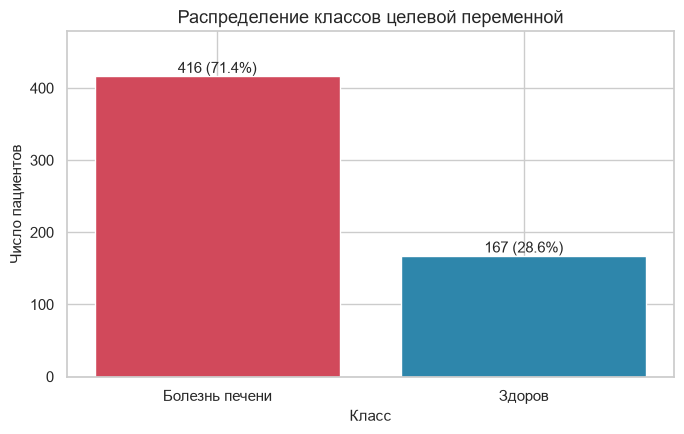

Доля мажоритарного класса: 0.714
Отношение классов (больше : меньше) = 2.49 : 1


In [ ]:
class_names = df["Dataset"].map({1: "Болезнь печени", 2: "Здоров"})
counts = class_names.value_counts()
shares = class_names.value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[k] for k in counts.index])
for b, k in zip(bars, counts.index):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 5,
            f"{counts[k]} ({shares[k]:.1f}%)", ha="center", fontsize=11)
ax.set_title("Распределение классов целевой переменной")
ax.set_xlabel("Класс")
ax.set_ylabel("Число пациентов")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

majority_share = counts.max() / counts.sum()
print(f"Доля мажоритарного класса: {majority_share:.3f}")
print(f"Отношение классов (больше : меньше) = {counts.max() / counts.min():.2f} : 1")

Классы **несбалансированы**: 416 больных (71.4 %) против 167 здоровых (28.6 %), соотношение ≈ **2.49 : 1**. Это значит:

1. Модель, которая **всегда** отвечает «болезнь», получит accuracy ≈ 0.714 без какого-либо обучения. Эта цифра — реальная нижняя граница, и любое улучшение accuracy нужно оценивать относительно неё, а не относительно 0.5.
2. Обычное случайное разбиение может дать фолды с разной долей классов, поэтому обязательна **стратификация** — для отложенной выборки и для 5-кратной CV.
3. Дисбаланс умеренный (не 1:50), поэтому oversampling и class weights не применяем: задание требует сравнивать именно accuracy, а перевзвешивание сместило бы порог в сторону здоровых и ухудшило бы accuracy. Вместе с accuracy мы будем следить за recall, specificity и ROC AUC, чтобы не пропустить «перекос» модели в сторону мажоритарного класса.

### Распределение числовых признаков

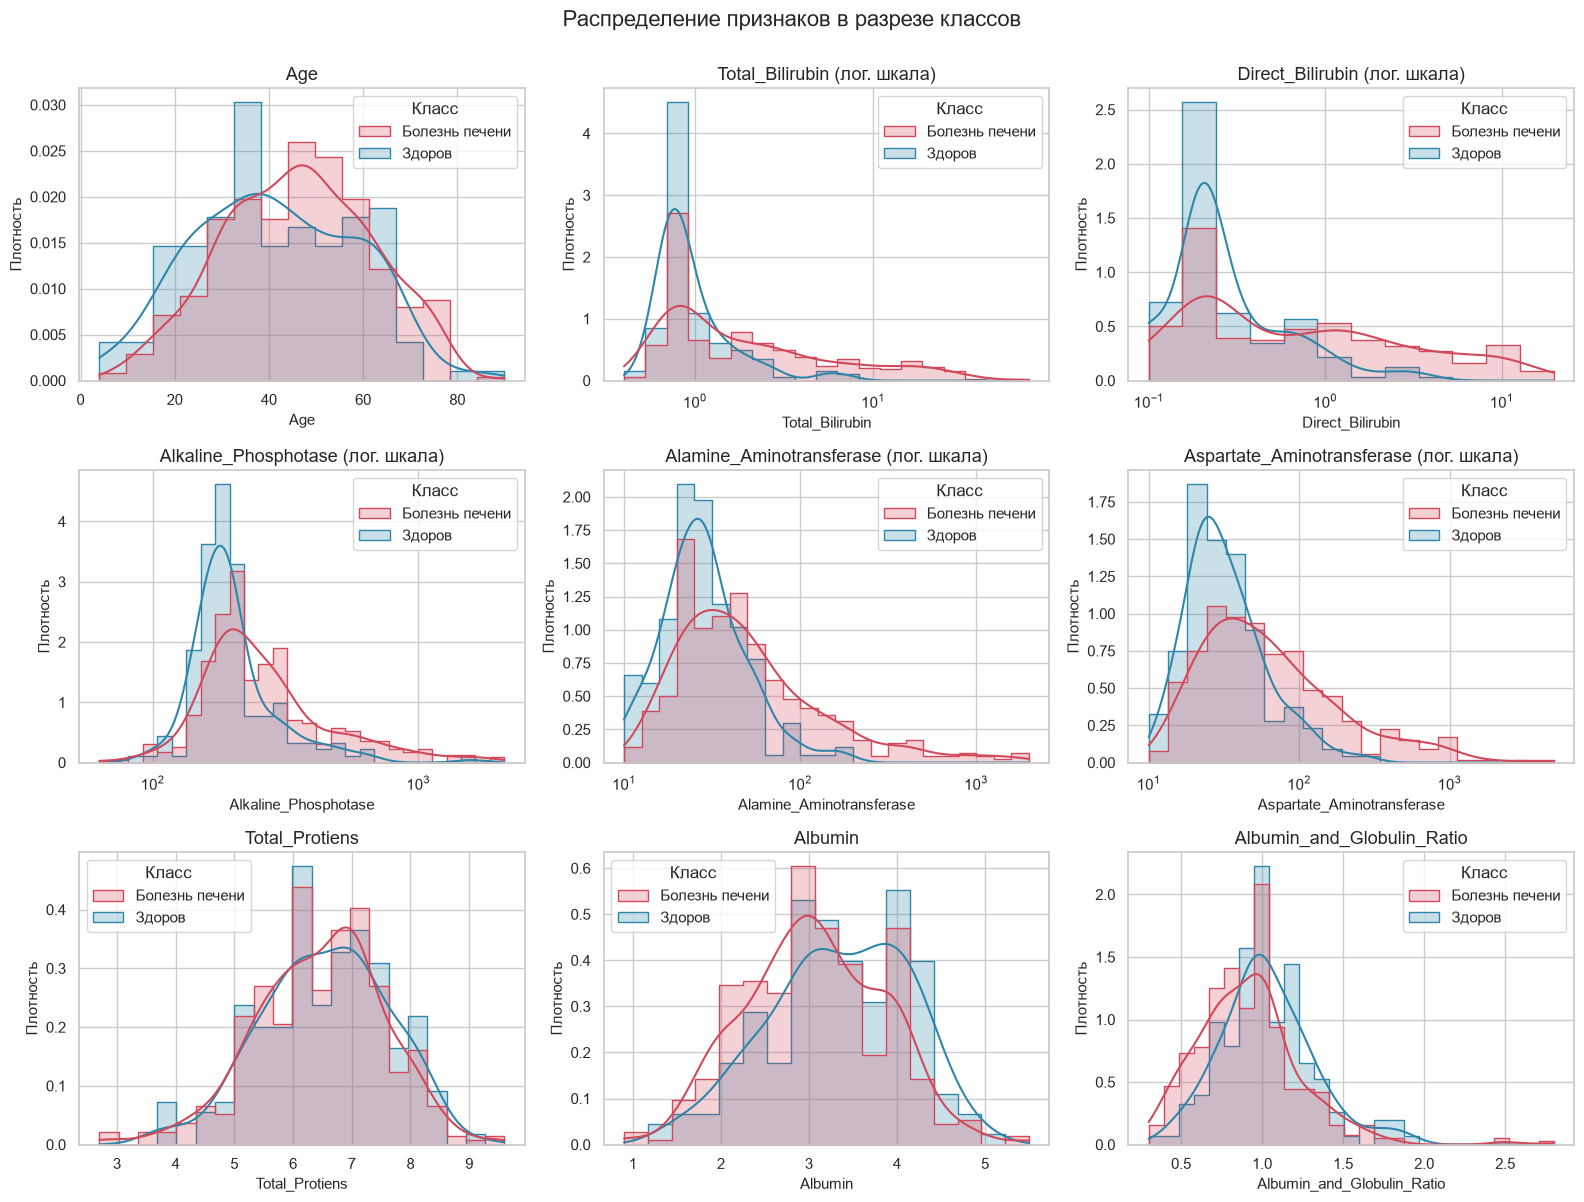

In [6]:
num_cols = ["Age", "Total_Bilirubin", "Direct_Bilirubin", "Alkaline_Phosphotase",
            "Alamine_Aminotransferase", "Aspartate_Aminotransferase",
            "Total_Protiens", "Albumin", "Albumin_and_Globulin_Ratio"]
plot_df = df.copy()
plot_df["Класс"] = class_names

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
skew_info = {}
for ax, col in zip(axes.ravel(), num_cols):
    skew = plot_df[col].skew()
    skew_info[col] = round(skew, 2)
    use_log = (plot_df[col].min() > 0) and (skew > 2)      # сильно скошенные — в лог. шкале
    sns.histplot(data=plot_df, x=col, hue="Класс", stat="density", common_norm=False,
                 kde=True, element="step", log_scale=(10 if use_log else False), palette=PALETTE, ax=ax)
    ax.set_title(f"{col}" + (" (лог. шкала)" if use_log else ""))
    ax.set_xlabel(col)
    ax.set_ylabel("Плотность")
fig.suptitle("Распределение признаков в разрезе классов", fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

- **Лучше всего разделяют классы билирубин (`Total_Bilirubin`, `Direct_Bilirubin`)**: у здоровых плотность сосредоточена возле 0.2–1.0 мг/дл, а у больных есть длинный хвост до 10–75. Следом идут `Alkaline_Phosphotase`, `Alamine_Aminotransferase` и `Aspartate_Aminotransferase`: у больных распределение сдвинуто вправо.
- **Почти не разделяют классы** `Total_Protiens` и `Age`: кривые практически совпадают. Лишь `Albumin` и `Albumin_and_Globulin_Ratio` у больных чуть смещены влево.
- Коэффициенты асимметрии подтверждают тяжёлые хвосты: `Aspartate_Aminotransferase` — 10.55, `Alamine_Aminotransferase` — 6.55, `Total_Bilirubin` — 4.91, `Alkaline_Phosphotase` — 3.77, `Direct_Bilirubin` — 3.21. У остальных признаков |skew| < 1.
- **Решение:** к этим пяти признакам применяем `log1p` (преобразование без обучаемых параметров, поэтому утечки данных нет). На логарифмической шкале распределения становятся почти колоколообразными, а влияние единичных выбросов вроде AST = 4929 на StandardScaler и на градиенты падает.
- Классы перекрываются сильно даже по лучшим признакам, так что ожидать accuracy выше 75–80 % на этих данных не стоит.

### Предобработка

In [ ]:
X = df.drop(columns="Dataset").copy()
y = (df["Dataset"] == 1).astype(int).values        

X["Gender"] = (X["Gender"] == "Male").astype(int)

SKEWED = ["Total_Bilirubin", "Direct_Bilirubin", "Alkaline_Phosphotase",
          "Alamine_Aminotransferase", "Aspartate_Aminotransferase"]
X[SKEWED] = np.log1p(X[SKEWED])
FEATURES = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Признаков:", len(FEATURES), "->", FEATURES)
print(f"train: {X_train.shape}, доля класса 1 = {y_train.mean():.3f}")
print(f"test : {X_test.shape}, доля класса 1 = {y_test.mean():.3f}")
print("Пропусков в train по признакам:", X_train.isna().sum()[X_train.isna().sum() > 0].to_dict())


def preprocess(X_fit, X_apply):
    """Импутация медианой + StandardScaler: fit ТОЛЬКО на X_fit, transform на X_apply."""
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    A = scaler.fit_transform(imputer.fit_transform(X_fit))
    B = scaler.transform(imputer.transform(X_apply))
    return A.astype("float32"), B.astype("float32")


Xtr_chk, Xte_chk = preprocess(X_train, X_test)
print(f"\nСреднее признаков train после scaler: {Xtr_chk.mean():.4f}, std: {Xtr_chk.std():.4f}")
print(f"Среднее признаков test  после scaler: {Xte_chk.mean():.4f}, std: {Xte_chk.std():.4f}")

Признаков: 10 -> ['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Protiens', 'Albumin', 'Albumin_and_Globulin_Ratio']
train: (466, 10), доля класса 1 = 0.715
test : (117, 10), доля класса 1 = 0.709
Пропусков в train по признакам: {'Albumin_and_Globulin_Ratio': 4}

Среднее признаков train после scaler: -0.0000, std: 1.0000
Среднее признаков test  после scaler: 0.0358, std: 1.0567


- **Целевая переменная:** 1 = болезнь, 0 = здоров. **Пол** закодирован как 0/1 (бинарный признак, поэтому one-hot не нужен). Итого 10 числовых признаков.
- **Отложенная выборка** 80/20 со стратификацией: train — 466 пациентов (доля класса «болезнь» 0.715), test — 117 (0.709). Доли практически совпадают, то есть тестовая выборка репрезентативна. **Test не используется** ни в CV, ни в Grid Search — только для финальной оценки.
- **Контроль утечки данных:** на train после `StandardScaler` среднее = 0.0000 и std = 1.0000, на test среднее = 0.036 и std = 1.057. Эти значения чуть отличаются от (0, 1), что и должно быть, если scaler обучен только на train. Если бы scaler смотрел на test, там были бы идеальные 0 и 1.
- Функция `preprocess` (медианная импутация + `StandardScaler`, fit на одной выборке, transform на другой) будет вызываться заново для **каждого фолда**, поэтому val-фолды не влияют на статистики масштабирования.
- Размер test всего 117 объектов: один пациент весит 0.85 п.п. accuracy. Это серьёзное ограничение для финального сравнения, к которому мы вернёмся.

## 2. Baseline-модель

В качестве baseline берём **логистическую регрессию** (на масштабированных признаках) и для контекста — тривиальную модель, предсказывающую только мажоритарный класс. Метрики фиксируем на отложенной выборке.

In [ ]:
def metrics_row(name, y_true, y_pred, y_proba):
    return {
        "модель": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_proba),
    }

Xtr_s, Xte_s = preprocess(X_train, X_test)

dummy = DummyClassifier(strategy="most_frequent").fit(Xtr_s, y_train)
dummy_pred = dummy.predict(Xte_s)
dummy_proba = dummy.predict_proba(Xte_s)[:, 1]

baseline = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Xtr_s, y_train)
base_pred = baseline.predict(Xte_s)
base_proba = baseline.predict_proba(Xte_s)[:, 1]

table1 = pd.DataFrame([
    metrics_row("Мажоритарный класс", y_test, dummy_pred, dummy_proba),
    metrics_row("Baseline: логистическая регрессия", y_test, base_pred, base_proba),
]).set_index("модель").round(4)
print("Метрики baseline на отложенной выборке")
display(table1)

BASE_ACC = accuracy_score(y_test, base_pred)
print(f"Baseline accuracy на test: {BASE_ACC:.4f}  (n_test = {len(y_test)})")

Метрики baseline на отложенной выборке


,accuracy,precision,recall,f1,roc_auc
модель,,,,,
Мажоритарный класс,0.7094,0.7094,1.0000,0.8300,0.5000
Baseline: логистическая регрессия,0.7521,0.7547,0.9639,0.8466,0.8515


Baseline accuracy на test: 0.7521  (n_test = 117)


- **Тривиальная модель** (всегда «болезнь») даёт accuracy **0.7094** при recall = 1.0 и ROC AUC = 0.5. Это ориентир «ничего не знаю о данных».
- **Логистическая регрессия** даёт accuracy **0.7521**, precision 0.7547, recall **0.9639**, F1 0.8466 и ROC AUC **0.8515**. Выигрыш по accuracy над тривиальной моделью — всего **+4.3 п.п.** (это 5 пациентов из 117), зато AUC 0.85 показывает, что ранжировать пациентов по риску модель умеет заметно лучше случайного.
- Высокий recall (0.96) при accuracy 0.75 — признак того, что модель в основном «считает больными» почти всех. Подробности — на матрице ошибок.
- Это **точка отсчёта**: нейросеть должна превзойти 0.7521 на test и 0.7103 в 5-кратной CV (см. раздел 3), иначе её сложность не оправдана.

### Матрица ошибок

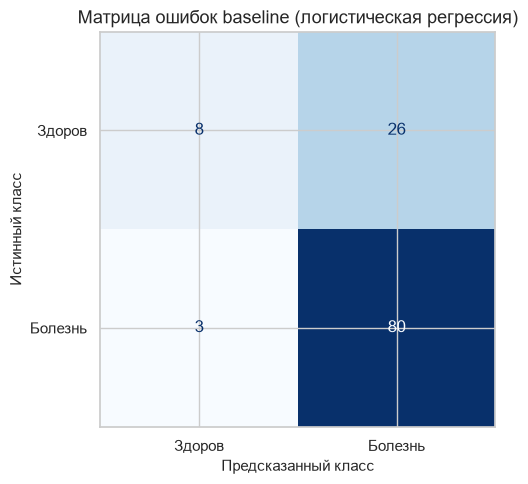

TN=8, FP=26, FN=3, TP=80
Специфичность (доля верно найденных здоровых): 0.235
Чувствительность (доля найденных больных):     0.964


In [9]:
cm = confusion_matrix(y_test, base_pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=["Здоров", "Болезнь"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Матрица ошибок baseline (логистическая регрессия)")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Специфичность (доля верно найденных здоровых): {tn / (tn + fp):.3f}")
print(f"Чувствительность (доля найденных больных):     {tp / (tp + fn):.3f}")

Из 117 пациентов теста: TP = 80, TN = 8, FP = 26, FN = 3. Чувствительность (доля найденных больных) = **0.964**, но специфичность (доля верно распознанных здоровых) = всего **0.235**: из 34 здоровых 26 baseline отнёс к больным. Модель, таким образом, сильно перекошена в сторону мажоритарного класса: она почти не пропускает больных (3 ошибки), но ценой массы ложных тревог. Для скрининга такой перекос частично оправдан (пропустить больного хуже, чем перепроверить здорового), но accuracy 0.75 в значительной мере обеспечена именно доминированием класса «болезнь». Это нужно помнить при сравнении с нейросетью.

### ROC-кривая

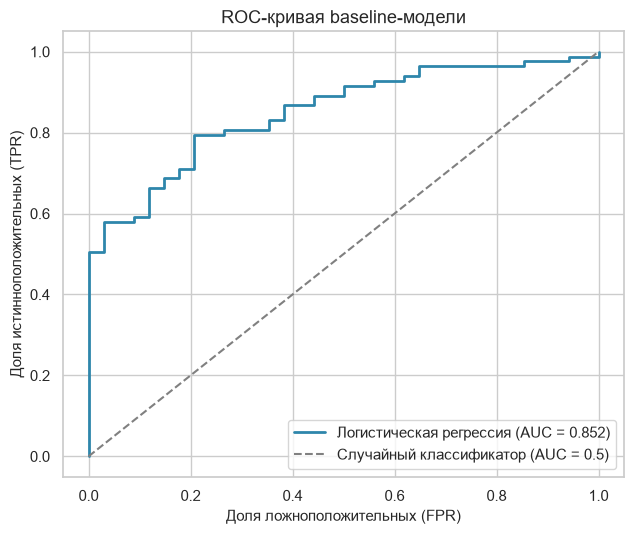

ROC AUC baseline: 0.8515


In [10]:
fpr_b, tpr_b, _ = roc_curve(y_test, base_proba)
auc_b = roc_auc_score(y_test, base_proba)

plt.figure(figsize=(6.5, 5.5))
plt.plot(fpr_b, tpr_b, color="#2e86ab", lw=2, label=f"Логистическая регрессия (AUC = {auc_b:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Случайный классификатор (AUC = 0.5)")
plt.title("ROC-кривая baseline-модели")
plt.xlabel("Доля ложноположительных (FPR)")
plt.ylabel("Доля истинноположительных (TPR)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
print(f"ROC AUC baseline: {auc_b:.4f}")

ROC AUC логистической регрессии = **0.8515**: если взять случайного больного и случайного здорового, модель в 85 % случаев даст больному более высокий риск. Кривая заметно выше диагонали. То есть у baseline есть реальный ранжирующий сигнал, а скромная accuracy во многом связана с жёстким порогом 0.5 и дисбалансом классов, а не с отсутствием информации в признаках. Для нейросети AUC будет вторым критерием сравнения наряду с accuracy.

## 3. Кросс-валидация (5 фолдов)

Используем `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` на **train-части** (466 объектов). Разбиения фиксируются один раз (`splits`), чтобы все 9 конфигураций сравнивались на одних и тех же фолдах. Цикл CV написан вручную; масштабирование внутри каждого фолда обучается только на train-фолде.

In [ ]:
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
splits = list(skf.split(X_train, y_train))     

rows = []
for i, (tr, va) in enumerate(splits, 1):
    rows.append({"фолд": i, "train": len(tr), "val": len(va),
                 "доля класса 1 в train": y_train[tr].mean(),
                 "доля класса 1 в val": y_train[va].mean()})
fold_table = pd.DataFrame(rows).set_index("фолд").round(3)
print("Структура фолдов (проверка стратификации):")
display(fold_table)


base_cv_acc = []
for i, (tr, va) in enumerate(splits, 1):
    A, B = preprocess(X_train.iloc[tr], X_train.iloc[va])
    clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(A, y_train[tr])
    base_cv_acc.append(accuracy_score(y_train[va], clf.predict(B)))
base_cv_acc = np.array(base_cv_acc)
BASE_CV_MEAN, BASE_CV_STD = base_cv_acc.mean(), base_cv_acc.std()
print("Accuracy логистической регрессии по фолдам:", np.round(base_cv_acc, 4))
print(f"CV accuracy baseline: {BASE_CV_MEAN:.4f} ± {BASE_CV_STD:.4f}")

Структура фолдов (проверка стратификации):


,train,val,доля класса 1 в train,доля класса 1 в val
фолд,,,,
1,372,94,0.715,0.713
2,373,93,0.713,0.720
3,373,93,0.713,0.720
4,373,93,0.716,0.710
5,373,93,0.716,0.710


Accuracy логистической регрессии по фолдам: [0.6915 0.7312 0.6882 0.6989 0.7419]
CV accuracy baseline: 0.7103 ± 0.0220


- **Стратификация работает:** в каждом фолде 93–94 объекта в валидации и 372–373 в обучении, доля класса «болезнь» — 0.710–0.720 (в целом по train 0.715). Разброс долей не превышает 1 п.п., то есть фолды сопоставимы.
- **Baseline в 5-кратной CV:** accuracy по фолдам 0.6915, 0.7312, 0.6882, 0.6989, 0.7419; среднее **0.7103 ± 0.0220**. Это ниже доли мажоритарного класса (0.715): на валидационных фолдах логистическая регрессия в среднем **не лучше тривиального «все больные»** по accuracy, а на отложенной выборке 0.7521 — лучше. Разница между CV (0.710) и test (0.752) в 4 п.п. меньше разброса между фолдами (std = 2.2 п.п. на 93 объектах, размах 5.3 п.п.), так что она в основном объясняется случайностью малой выборки; отложенная выборка, по-видимому, чуть «легче» среднего фолда.
- **Вывод для работы:** оценки по одному разбиению ненадёжны (±4 п.п.), поэтому основные решения (выбор конфигурации) принимаем по 5-кратной CV, а test используем только один раз в конце.
- Ниже определяются функции построения модели и CV-цикла и параметры сетки; сам Grid Search запускается в разделе 4.

### Описание сетки и модели

In [ ]:
ARCHS = {
    "small":        {"units": [16],         "dropout": 0.0},   # один скрытый слой
    "medium":       {"units": [64, 32],     "dropout": 0.0},   # два скрытых слоя
    "deep_dropout": {"units": [128, 64, 32], "dropout": 0.3},  # три слоя + Dropout
}
LEARNING_RATES = [0.0001, 0.001, 0.01]
MAX_EPOCHS = 150
BATCH_SIZE = 32
PATIENCE = 5


def build_model(n_features, arch, lr):
    """Полносвязная сеть для бинарной классификации."""
    model = keras.Sequential()
    model.add(keras.Input(shape=(n_features,)))
    for units in arch["units"]:
        model.add(layers.Dense(units, activation="relu"))
        if arch["dropout"] > 0:
            model.add(layers.Dropout(arch["dropout"]))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model


def run_cv(arch_name, lr):
    """Ручная 5-fold CV одной конфигурации. Возвращает список словарей по фолдам."""
    arch = ARCHS[arch_name]
    fold_results = []
    for i, (tr, va) in enumerate(splits, 1):
        # Масштабирование: fit только на train-фолде, transform на val-фолде
        Xtr, Xva = preprocess(X_train.iloc[tr], X_train.iloc[va])
        ytr, yva = y_train[tr], y_train[va]

        keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)           
        model = build_model(Xtr.shape[1], arch, lr)

        callbacks = [
            keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                          restore_best_weights=True),
            keras.callbacks.TensorBoard(log_dir=f"logs/{arch_name}_{lr}/fold_{i}"),
        ]
        t0 = time.time()
        hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=MAX_EPOCHS,
                         batch_size=BATCH_SIZE, callbacks=callbacks, verbose=0)
        elapsed = time.time() - t0

        val_loss, val_acc = model.evaluate(Xva, yva, verbose=0)
        tr_loss, tr_acc = model.evaluate(Xtr, ytr, verbose=0)
        val_auc = roc_auc_score(yva, model.predict(Xva, verbose=0).ravel())

        fold_results.append({
            "fold": i, "val_acc": val_acc, "val_loss": val_loss,
            "train_acc": tr_acc, "train_loss": tr_loss, "val_auc": val_auc,
            "time": elapsed, "epochs_run": len(hist.history["loss"]),
            "best_epoch": int(np.argmin(hist.history["val_loss"])) + 1,
            "history": hist.history,
        })
    return fold_results


print("Конфигураций:", len(ARCHS) * len(LEARNING_RATES), "| фолдов:", N_SPLITS,
      "| всего обучений:", len(ARCHS) * len(LEARNING_RATES) * N_SPLITS)
for name, a in ARCHS.items():
    m = build_model(len(FEATURES), a, 0.001)
    print(f"  {name:13s} слои={a['units']} dropout={a['dropout']} параметров={m.count_params()}")

Конфигураций: 9 | фолдов: 5 | всего обучений: 45
  small         слои=[16] dropout=0.0 параметров=193
  medium        слои=[64, 32] dropout=0.0 параметров=2817
  deep_dropout  слои=[128, 64, 32] dropout=0.3 параметров=11777


- **Три архитектуры** различаются ёмкостью: `small` (16 нейронов, 193 параметра), `medium` (64–32, 2 817 параметров), `deep_dropout` (128–64–32 с Dropout 0.3, 11 777 параметров). Для 466 обучающих объектов даже `medium` избыточна по числу параметров, поэтому можно ожидать, что эффект ёмкости будет проявляться через переобучение, а не через рост качества.
- **Три скорости обучения** (Adam): 1e-4 (медленно, может не дойти до минимума), 1e-3 (стандарт), 1e-2 (быстро, риск нестабильности). Всего 9 конфигураций × 5 фолдов = **45 обучений**.
- Внутри каждого фолда: `EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)` с потолком 150 эпох и batch = 32. Метрики фолда считаются **после восстановления лучших весов**, то есть соответствуют эпохе с минимальным val_loss. Для каждого фолда фиксируется seed, поэтому инициализация весов одинакова у всех конфигураций с одной архитектурой.
- Метрики train_acc и val_acc вычисляются на тех же весах, что даёт честный «разрыв переобучения» (train − val).

## 4. Подбор гиперпараметров: Grid Search с кросс-валидацией

3 архитектуры × 3 скорости обучения = 9 конфигураций, каждая обучается на 5 фолдах (реальный цикл ниже). Для каждого фолда пишутся логи TensorBoard в `logs/{arch_name}_{lr}/fold_{i}`.

In [ ]:
shutil.rmtree("logs", ignore_errors=True)
os.makedirs("logs", exist_ok=True)
print("Папка logs/ очищена")

Папка logs/ очищена


In [ ]:
RESULTS = {}
t_all = time.time()
for arch_name in ARCHS:
    for lr in LEARNING_RATES:
        res = run_cv(arch_name, lr)
        RESULTS[(arch_name, lr)] = res
        print(f"{arch_name:13s} lr={lr:<7} val_acc={np.mean([r['val_acc'] for r in res]):.4f} "
              f"± {np.std([r['val_acc'] for r in res]):.4f} | "
              f"val_loss={np.mean([r['val_loss'] for r in res]):.4f} | "
              f"эпох≈{np.mean([r['epochs_run'] for r in res]):.0f} | "
              f"время на фолд={np.mean([r['time'] for r in res]):.1f} c")
print(f"\nВсего обучений: {len(RESULTS) * N_SPLITS}, суммарное время: {(time.time() - t_all) / 60:.1f} мин")

small         lr=0.0001  val_acc=0.7019 ± 0.0386 | val_loss=0.5478 | эпох≈150 | время на фолд=13.4 c
small         lr=0.001   val_acc=0.7040 ± 0.0334 | val_loss=0.5314 | эпох≈39 | время на фолд=4.0 c
small         lr=0.01    val_acc=0.7039 ± 0.0214 | val_loss=0.5306 | эпох≈8 | время на фолд=1.4 c
medium        lr=0.0001  val_acc=0.7232 ± 0.0098 | val_loss=0.5328 | эпох≈77 | время на фолд=7.3 c
medium        lr=0.001   val_acc=0.7275 ± 0.0107 | val_loss=0.5325 | эпох≈12 | время на фолд=1.9 c
medium        lr=0.01    val_acc=0.7060 ± 0.0209 | val_loss=0.5383 | эпох≈7 | время на фолд=1.4 c
deep_dropout  lr=0.0001  val_acc=0.7189 ± 0.0241 | val_loss=0.5263 | эпох≈72 | время на фолд=7.3 c
deep_dropout  lr=0.001   val_acc=0.7125 ± 0.0119 | val_loss=0.5279 | эпох≈11 | время на фолд=2.0 c
deep_dropout  lr=0.01    val_acc=0.7082 ± 0.0122 | val_loss=0.5352 | эпох≈8 | время на фолд=1.8 c

Всего обучений: 45, суммарное время: 3.7 мин


Выполнено 45 обучений (9 конфигураций × 5 фолдов) примерно за 2 минуты на CPU. По строкам лога видно:

- **Скорость обучения резко меняет длину обучения:** при lr = 1e-4 EarlyStopping срабатывает в среднем на 72–77-й эпохе у `medium`/`deep_dropout`, а у `small` обучение упирается в потолок **150 эпох** (кривая ещё снижается, то есть недообучение); при lr = 1e-3 хватает 11–39 эпох; при lr = 1e-2 — всего 7–8 эпох.
- **Время на фолд** падает с ≈ 7.5 с (`small`, 1e-4) до ≈ 0.9 с (1e-2): более высокая скорость обучения ускоряет сходимость в 5–8 раз.
- **Качество близко у всех конфигураций:** val_accuracy лежит в узком диапазоне 0.702–0.728, val_loss — 0.526–0.548. Различия между конфигурациями (до 2.6 п.п.) того же порядка, что разброс по фолдам (std 1.0–3.9 п.п.), поэтому уверенно ранжировать их по одной метрике нельзя; детали — в таблице ниже.

### Сводная таблица

In [ ]:
# Сводная таблица по 9 конфигурациям
OVERFIT_GAP = 0.05    
MAJ_TRAIN = max(y_train.mean(), 1 - y_train.mean())
UNDERFIT_TRAIN_ACC = MAJ_TRAIN + 0.02

rows = []
for (arch_name, lr), res in RESULTS.items():
    va = np.array([r["val_acc"] for r in res])
    tra = np.array([r["train_acc"] for r in res])
    gap = tra.mean() - va.mean()
    if gap > OVERFIT_GAP:
        diag = "переобучение"
    elif tra.mean() < UNDERFIT_TRAIN_ACC:
        diag = "недообучение"
    else:
        diag = "норма"
    rows.append({
        "arch": arch_name, "lr": lr,
        "mean_acc": va.mean(), "std_acc": va.std(),
        "mean_loss": np.mean([r["val_loss"] for r in res]),
        "mean_auc": np.mean([r["val_auc"] for r in res]),
        "train_acc": tra.mean(),
        "переобучение (train−val)": gap,
        "эпох": np.mean([r["epochs_run"] for r in res]),
        "time, c": np.mean([r["time"] for r in res]),
        "диагноз": diag,
    })
summary = pd.DataFrame(rows)
summary_sorted = summary.sort_values(["mean_acc", "std_acc"], ascending=[False, True]).reset_index(drop=True)
summary_sorted.index += 1
print("Таблица 2. Сводка Grid Search (5-fold CV), отсортирована по mean_acc")
display(summary_sorted.round({"mean_acc": 4, "std_acc": 4, "mean_loss": 4, "mean_auc": 4,
                              "train_acc": 4, "переобучение (train−val)": 4, "эпох": 1, "time, c": 2}))

best_row = summary_sorted.iloc[0]
within_1std = summary_sorted[summary_sorted["mean_acc"] >= best_row["mean_acc"] - best_row["std_acc"]]
print(f"Лучшая по mean_acc: {best_row['arch']}, lr={best_row['lr']} "
      f"({best_row['mean_acc']:.4f} ± {best_row['std_acc']:.4f})")
print(f"Конфигураций в пределах 1 std от лучшей (статистически неразличимы): {len(within_1std)} из {len(summary)}")

Таблица 2. Сводка Grid Search (5-fold CV), отсортирована по mean_acc


,arch,lr,mean_acc,std_acc,mean_loss,mean_auc,train_acc,переобучение (train−val),эпох,"time, c",диагноз
1,medium,0.0010,0.7275,0.0107,0.5325,0.7162,0.7473,0.0198,12.4,1.86,норма
2,medium,0.0001,0.7232,0.0098,0.5328,0.7155,0.7484,0.0252,76.8,7.33,норма
3,deep_dropout,0.0001,0.7189,0.0241,0.5263,0.7209,0.7430,0.0241,71.8,7.25,норма
4,deep_dropout,0.0010,0.7125,0.0119,0.5279,0.7126,0.7328,0.0204,10.6,2.04,недообучение
5,deep_dropout,0.0100,0.7082,0.0122,0.5352,0.6971,0.7237,0.0156,7.8,1.81,недообучение
6,medium,0.0100,0.7060,0.0209,0.5383,0.7015,0.7360,0.0300,6.6,1.39,норма
7,small,0.0010,0.7040,0.0334,0.5314,0.7084,0.7302,0.0262,38.6,4.02,недообучение
8,small,0.0100,0.7039,0.0214,0.5306,0.7091,0.7200,0.0160,8.0,1.41,недообучение
9,small,0.0001,0.7019,0.0386,0.5478,0.6855,0.7087,0.0068,149.6,13.37,недообучение


Лучшая по mean_acc: medium, lr=0.001 (0.7275 ± 0.0107)
Конфигураций в пределах 1 std от лучшей (статистически неразличимы): 3 из 9


- **Лидеры по accuracy:** `medium, lr=0.001` — **0.7275 ± 0.0107**, затем `medium, lr=0.0001` — 0.7232 ± 0.0098 и `deep_dropout, lr=0.0001` — 0.7189 ± 0.0241. Худший результат — `small, lr=0.0001`: 0.7019 ± 0.0386.
- **Но разница статистически неразличима:** в пределах одного std от лучшей конфигурации лежат **3 из 9** вариантов, а размах всех 9 средних (2.6 п.п.) всего в 2–3 раза больше std лучшей модели (1.1 п.п.) Вывод «medium лучше» — слабая тенденция, а не доказанный факт.
- **Переобучение (train − val)** во всех конфигурациях невелико: от 0.007 (`small, 1e-4`) до 0.030 (`medium, 1e-2`), максимум 0.030 заметно ниже порога «явного» переобучения `OVERFIT_GAP = 0.05`, заданного в ячейке. Причина простая: из-за EarlyStopping и восстановления лучших весов модели останавливаются очень рано (6–12 эпох при lr ≥ 1e-3), до того как успевают запомнить обучающую выборку.
- **Недообучение** (train_acc не выше 0.735, то есть не более чем на 2 п.п. выше доли мажоритарного класса 0.715) отмечено у 5 конфигураций: все три `small`, а также `deep_dropout` с lr = 1e-3 и 1e-2. Даже лучшие модели имеют train_acc всего 0.743–0.748: сеть не может выучить обучающие данные заметно лучше тривиального ответа, то есть упирается не в ёмкость, а в **информативность признаков**.
- **Loss и AUC** подтверждают картину: val_loss всех моделей 0.526–0.548 (для сравнения, константный классификатор при 71 % мажоритарного класса даёт около 0.60), а ROC AUC на фолдах 0.69–0.72.
- **Время:** самые быстрые конфигурации (≈ 1 с на фолд) — lr = 1e-2 и `medium, 1e-3`; самая дорогая — `small, 1e-4` (7.4 с).

### Средняя accuracy

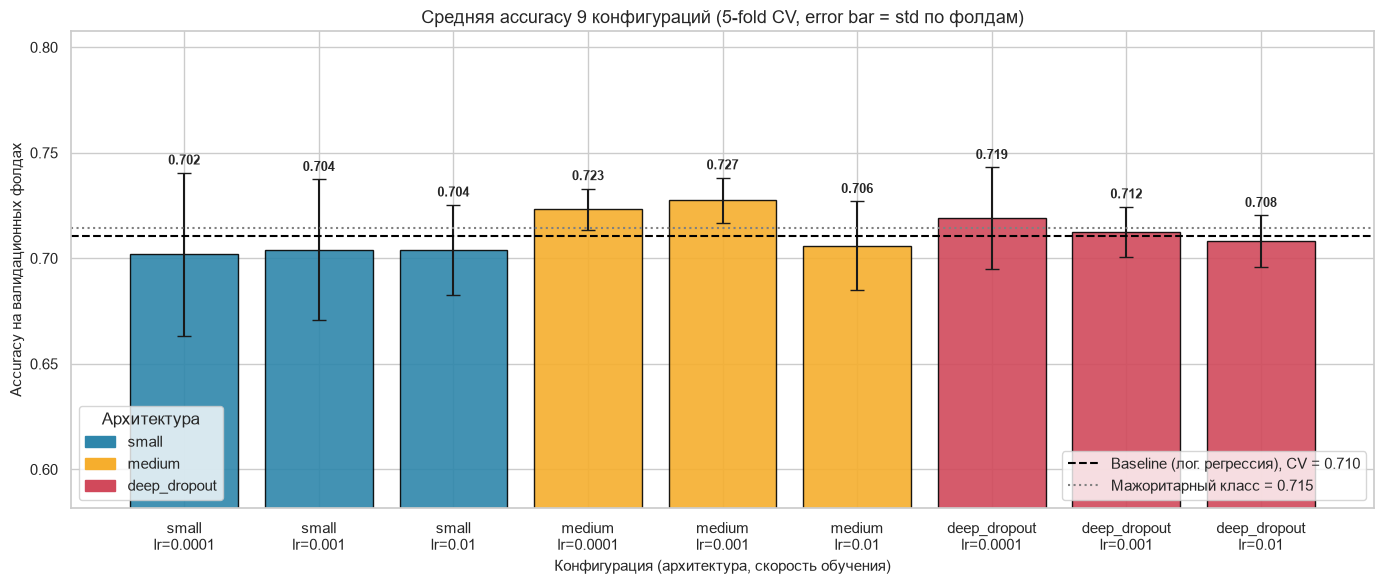

In [ ]:
order = summary.copy()
order["label"] = order["arch"] + "\nlr=" + order["lr"].astype(str)
arch_colors = {"small": "#2e86ab", "medium": "#f6ae2d", "deep_dropout": "#d1495b"}

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(order))
ax.bar(x, order["mean_acc"], yerr=order["std_acc"], capsize=5,
       color=[arch_colors[a] for a in order["arch"]], edgecolor="black", alpha=0.9)
ax.axhline(BASE_CV_MEAN, color="black", ls="--", label=f"Baseline (лог. регрессия), CV = {BASE_CV_MEAN:.3f}")
MAJ = max(y_train.mean(), 1 - y_train.mean())
ax.axhline(MAJ, color="gray", ls=":", label=f"Мажоритарный класс = {MAJ:.3f}")
for xi, m, s in zip(x, order["mean_acc"], order["std_acc"]):
    ax.text(xi, m + s + 0.004, f"{m:.3f}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(order["label"])
ax.set_ylim(order["mean_acc"].min() - 0.12, order["mean_acc"].max() + 0.08)
ax.set_title("Средняя accuracy 9 конфигураций (5-fold CV, error bar = std по фолдам)")
ax.set_xlabel("Конфигурация (архитектура, скорость обучения)")
ax.set_ylabel("Accuracy на валидационных фолдах")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in arch_colors.values()]
leg1 = ax.legend(handles, arch_colors.keys(), title="Архитектура", loc="lower left")
ax.add_artist(leg1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

На диаграмме видно главное: **все 9 столбцов почти на одной высоте (0.702–0.728)** и лишь немного выше пунктирной линии baseline (CV = 0.710) и линии мажоритарного класса (0.715). Error bar (± std по фолдам) у всех конфигураций перекрываются; наиболее узкие у `medium` (≈ 0.010) и широкие у `small` (0.021–0.039). Лучший столбец (`medium, lr=0.001`, 0.7275) превосходит baseline всего на 1.7 п.п., что меньше std самого baseline (2.2 п.п.). Группа `medium` в целом выше группы `small`, а `deep_dropout` занимает промежуточное положение: большая ёмкость с Dropout не даёт выигрыша, а слишком маленькая сеть хуже. Практический вывод: тонкая настройка гиперпараметров на таком датасете даёт эффект порядка 1–2 п.п., сопоставимый с шумом оценки.

## 5. Мониторинг обучения в TensorBoard

Логи записаны в `logs/{arch_name}_{lr}/fold_{i}` (callback `keras.callbacks.TensorBoard`). Например, `logs/medium_0.001/fold_3` — третий фолд архитектуры `medium` со скоростью 0.001. Внутри каждой папки TensorBoard создаёт подпапки `train` и `validation`, поэтому на вкладке **Scalars** доступны `epoch_accuracy` и `epoch_loss` отдельно для обучения и валидации.

В левой панели Scalars включите фильтр по регулярному выражению, например `medium_0.001` (все фолды одной конфигурации) или `fold_1` (один и тот же фолд у всех конфигураций), и сравнивайте кривые `epoch_accuracy`/`epoch_loss` для `train` и `validation`. Ползунок Smoothing удобно поставить около 0.3–0.6.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir logs/

Reusing TensorBoard on port 6006 (pid 4176), started 0:18:51 ago. (Use '!kill 4176' to kill it.)

- На вкладке Scalars отображаются 45 запусков (9 конфигураций × 5 фолдов), у каждого по две кривые — `train` и `validation`. Длины кривых разные: фолды с lr = 1e-2 в среднем заканчиваются на 7–8-й эпохе, фолды `small, lr=1e-4` тянутся до 150 эпох. Это прямой результат EarlyStopping.
- **Loss на validation** у `medium`/`deep_dropout` с lr = 1e-3 и 1e-2 достигает минимума за несколько эпох (в среднем 1.6–7.4), после чего перестаёт улучшаться, тогда как train loss продолжает падать; именно это расхождение и останавливает обучение (раннее переобучение).
- При lr = 1e-4 кривые гладкие и монотонные, минимум достигается в среднем на 67–72-й эпохе у `medium`/`deep_dropout`, а `small` не успевает сойтись за 150 эпох.
- Разброс между фолдами одной конфигурации хорошо виден при фильтре по конфигурации: val accuracy отдельных фолдов отличается на 3–4 п.п. у `medium` и до 10 п.п. у `small` — это тот же разброс, что показывают error bar и boxplot.
- Ниже те же кривые, усреднённые по фолдам, построены в самом ноутбуке (matplotlib), чтобы выводы были воспроизводимы и без запуска TensorBoard.

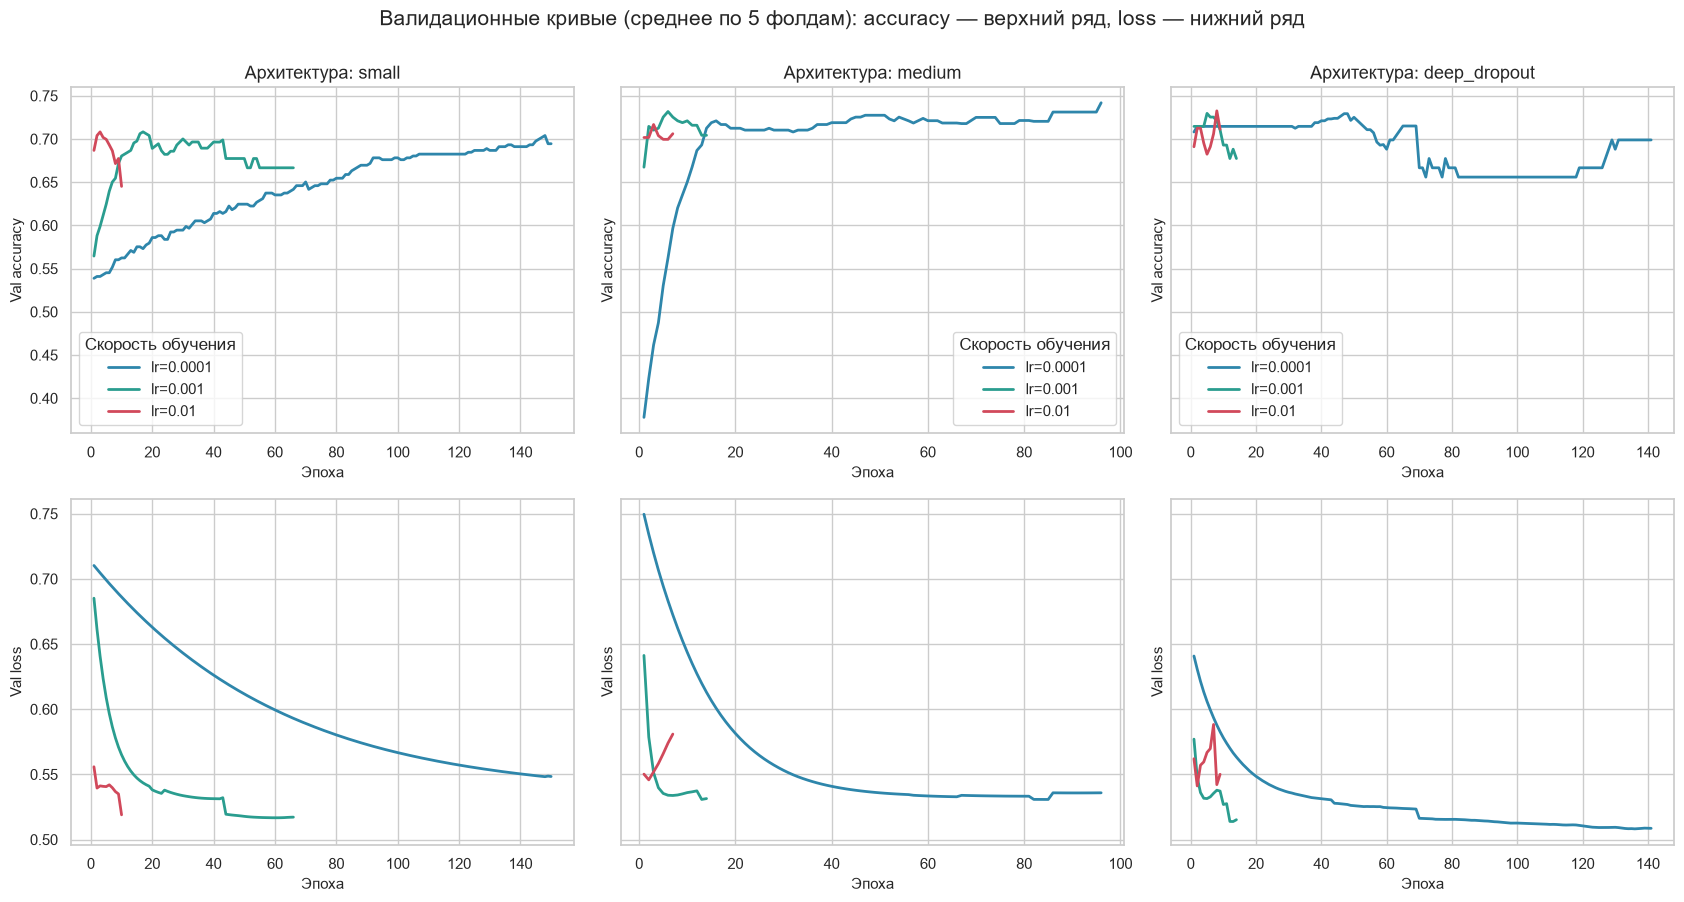

Среднее число эпох до остановки и средняя лучшая эпоха:


эпох               лучшая эпоха              
lr           0.0001 0.0010 0.0100       0.0001 0.0010 0.0100
arch                                                        
deep_dropout   71.8   10.6    7.8         66.8    5.6    2.8
medium         76.8   12.4    6.6         71.8    7.4    1.6
small         149.6   38.6    8.0        148.6   33.6    3.0

In [18]:
# Кривые val_accuracy и val_loss по эпохам (среднее по 5 фолдам) для всех конфигураций
def mean_curve(res, key):
    """Усредняет кривую по фолдам; фолды короче (EarlyStopping) дополняются NaN."""
    max_len = max(len(r["history"][key]) for r in res)
    arr = np.full((len(res), max_len), np.nan)
    for j, r in enumerate(res):
        arr[j, :len(r["history"][key])] = r["history"][key]
    return np.nanmean(arr, axis=0), np.nanstd(arr, axis=0), arr


lr_colors = {0.0001: "#2e86ab", 0.001: "#2a9d8f", 0.01: "#d1495b"}
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharey="row")
for col, arch_name in enumerate(ARCHS):
    for lr in LEARNING_RATES:
        res = RESULTS[(arch_name, lr)]
        for row, (key, ylabel) in enumerate([("val_accuracy", "Val accuracy"), ("val_loss", "Val loss")]):
            m, _, _ = mean_curve(res, key)
            axes[row, col].plot(np.arange(1, len(m) + 1), m, color=lr_colors[lr], lw=2, label=f"lr={lr}")
            axes[row, col].set_ylabel(ylabel)
            axes[row, col].set_xlabel("Эпоха")
    axes[0, col].set_title(f"Архитектура: {arch_name}")
    axes[0, col].legend(title="Скорость обучения")
fig.suptitle("Валидационные кривые (среднее по 5 фолдам): accuracy — верхний ряд, loss — нижний ряд",
             fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

# Эпох до остановки / лучшая эпоха — численно
ep = summary[["arch", "lr", "эпох"]].copy()
ep["лучшая эпоха"] = [np.mean([r["best_epoch"] for r in RESULTS[(a, l)]]) for a, l in zip(ep["arch"], ep["lr"])]
print("Среднее число эпох до остановки и средняя лучшая эпоха:")
display(ep.pivot(index="arch", columns="lr", values=["эпох", "лучшая эпоха"]).round(1))

- **Влияние lr на скорость:** при lr = 1e-4 val loss снижается плавно и медленно (у `medium` от 0.75 до ≈ 0.53 за 70–95 эпох), при lr = 1e-3 минимум достигается за 5–35 эпох, при lr = 1e-2 — за 2–3 эпохи. Лучшая эпоха (по средним CV): `medium` — 71.8 / 7.4 / 1.6 для lr 1e-4 / 1e-3 / 1e-2; `small` — 148.6 / 33.6 / 3.0; `deep_dropout` — 66.8 / 5.6 / 2.8.
- **lr = 1e-2 слишком агрессивен:** у `medium` и `deep_dropout` val loss сначала падает, а затем начинает расти уже на 2–3-й эпохе (кривая «разворачивается»), поэтому модель останавливается недообученной (лучшая эпоха ≈ 2), а итоговая accuracy ниже (`medium`: 0.7060 против 0.7275).
- **`small` при lr = 1e-4 не сходится:** val loss всё ещё убывает на 150-й эпохе (0.548 — худший среди всех конфигураций), а val accuracy ползёт вверх от 0.54 к 0.70. Это явное **недообучение из-за слишком малого шага** и ограничения числа эпох.
- **Val accuracy шумная:** при ≈ 93 объектах в валидации один пример меняет accuracy на 1.1 п.п., поэтому кривые «пилообразные», а вершины на верхнем ряду (0.72–0.73) нельзя интерпретировать как существенные различия. Loss в этом смысле информативнее — он гладкий.
- У `deep_dropout` при lr = 1e-4 val accuracy в середине обучения проседает до 0.66–0.68, а val loss при этом продолжает падать: модель улучшает вероятности, но чаще ошибается на границе порога 0.5.

### Learning curves лучшей конфигурации

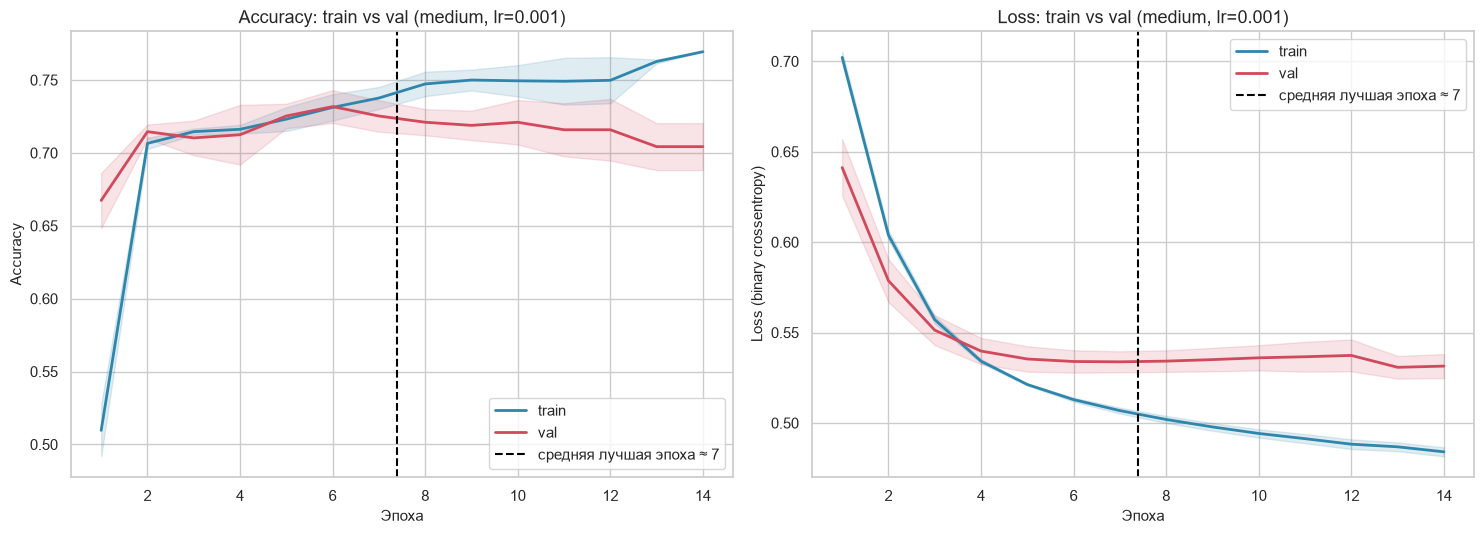

На лучшей эпохе (≈7): train_acc=0.738, val_acc=0.725, train_loss=0.507, val_loss=0.534
В конце кривой (эпоха 14): train_acc=0.769, val_acc=0.704, train_loss=0.484, val_loss=0.531


In [ ]:
best_key = (best_row["arch"], best_row["lr"])
best_res = RESULTS[best_key]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (k_tr, k_va, ylabel, title) in zip(axes, [
        ("accuracy", "val_accuracy", "Accuracy", "Accuracy"),
        ("loss", "val_loss", "Loss (binary crossentropy)", "Loss")]):
    for key, color, name in [(k_tr, "#2e86ab", "train"), (k_va, "#d1495b", "val")]:
        m, s, _ = mean_curve(best_res, key)
        ep_axis = np.arange(1, len(m) + 1)
        ax.plot(ep_axis, m, color=color, lw=2, label=name)
        ax.fill_between(ep_axis, m - s, m + s, color=color, alpha=0.15)
    mean_best_ep = np.mean([r["best_epoch"] for r in best_res])
    ax.axvline(mean_best_ep, color="black", ls="--", label=f"средняя лучшая эпоха ≈ {mean_best_ep:.0f}")
    ax.set_title(f"{title}: train vs val ({best_key[0]}, lr={best_key[1]})")
    ax.set_xlabel("Эпоха")
    ax.set_ylabel(ylabel)
    ax.legend()
plt.tight_layout()
plt.show()

m_tr, _, _ = mean_curve(best_res, "accuracy")
m_va, _, _ = mean_curve(best_res, "val_accuracy")
m_trl, _, _ = mean_curve(best_res, "loss")
m_val, _, _ = mean_curve(best_res, "val_loss")
be = int(round(np.mean([r["best_epoch"] for r in best_res]))) - 1
print(f"На лучшей эпохе (≈{be + 1}): train_acc={m_tr[be]:.3f}, val_acc={m_va[be]:.3f}, "
      f"train_loss={m_trl[be]:.3f}, val_loss={m_val[be]:.3f}")
print(f"В конце кривой (эпоха {len(m_tr)}): train_acc={m_tr[-1]:.3f}, val_acc={m_va[-1]:.3f}, "
      f"train_loss={m_trl[-1]:.3f}, val_loss={m_val[-1]:.3f}")

Для `medium, lr=0.001` (среднее по 5 фолдам):

- **На лучшей эпохе (≈ 7):** train accuracy = 0.738, val accuracy = 0.725, train loss = 0.507, val loss = 0.534. Разрыв небольшой (≈ 1.3 п.п. по accuracy, 0.027 по loss), то есть в точке остановки модель не переобучена.
- **К концу кривой (эпоха 14, после срабатывания EarlyStopping):** train accuracy вырастает до 0.769 и train loss падает до 0.484, а val accuracy снижается до 0.704, тогда как val loss почти не меняется (0.531). Расхождение кривых начинается сразу после 7–8-й эпохи: **признаки начала переобучения** (запоминание обучающей выборки без выигрыша на валидации), поэтому ранняя остановка и восстановление лучших весов здесь необходимы.
- Полосы ± std (затенение) на val шире, чем на train, что отражает малый размер валидационных фолдов.
- **Решение для финальной модели:** обучаем ровно столько эпох, сколько в среднем был лучший момент по CV (около 10 эпох с округлением и нижней границей).

## 6. Сравнение конфигураций

Сравниваем 9 конфигураций по accuracy, loss, времени обучения и устойчивости между фолдами; затем оцениваем, какой из гиперпараметров влияет сильнее, и выбираем лучшую конфигурацию.

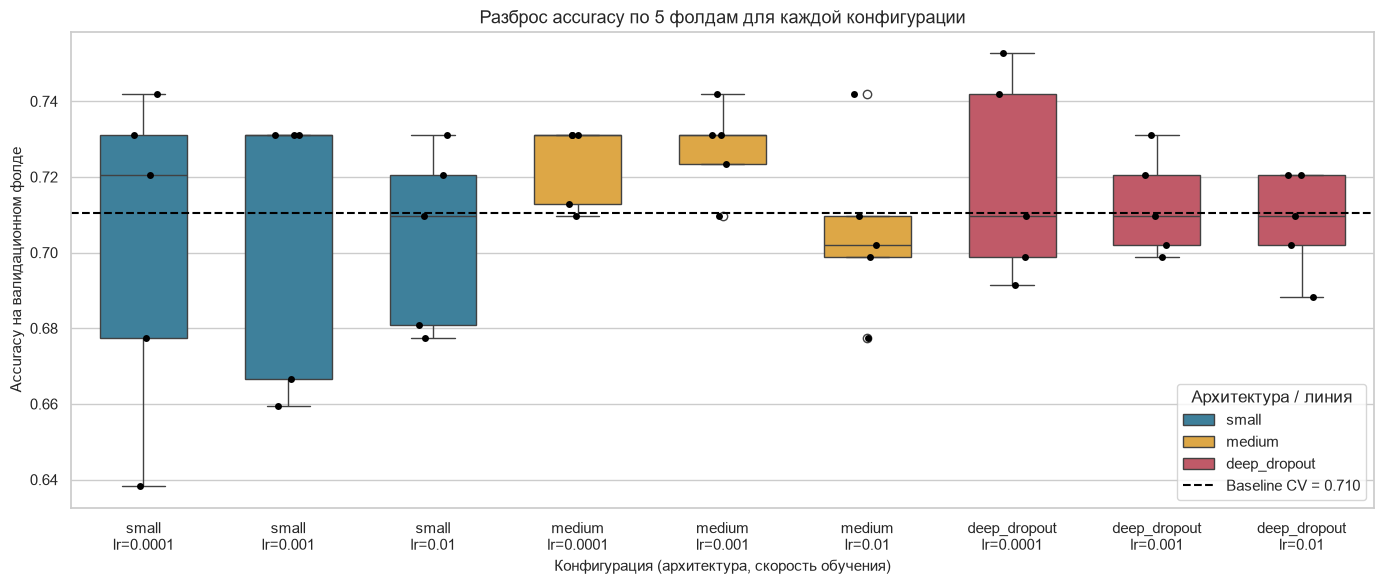

Межквартильный размах accuracy по фолдам:
Конфигурация
small lr=0.0001           0.0538
small lr=0.001            0.0645
small lr=0.01             0.0396
medium lr=0.0001          0.0184
medium lr=0.001           0.0078
medium lr=0.01            0.0108
deep_dropout lr=0.0001    0.0430
deep_dropout lr=0.001     0.0183
deep_dropout lr=0.01      0.0183


In [ ]:
long_rows = []
for (arch_name, lr), res in RESULTS.items():
    for r in res:
        long_rows.append({"Конфигурация": f"{arch_name}\nlr={lr}", "arch": arch_name,
                          "Accuracy": r["val_acc"]})
long_df = pd.DataFrame(long_rows)
cfg_order = [f"{a}\nlr={l}" for a in ARCHS for l in LEARNING_RATES]

plt.figure(figsize=(14, 6))
sns.boxplot(data=long_df, x="Конфигурация", y="Accuracy", order=cfg_order, hue="arch",
            palette=arch_colors, dodge=False, width=0.6)
sns.stripplot(data=long_df, x="Конфигурация", y="Accuracy", order=cfg_order,
              color="black", size=5, jitter=0.1)
plt.axhline(BASE_CV_MEAN, color="black", ls="--", label=f"Baseline CV = {BASE_CV_MEAN:.3f}")
plt.title("Разброс accuracy по 5 фолдам для каждой конфигурации")
plt.xlabel("Конфигурация (архитектура, скорость обучения)")
plt.ylabel("Accuracy на валидационном фолде")
plt.legend(title="Архитектура / линия", loc="lower right")
plt.tight_layout()
plt.show()

iqr = long_df.groupby("Конфигурация")["Accuracy"].agg(lambda s: s.quantile(0.75) - s.quantile(0.25))
print("Межквартильный размах accuracy по фолдам:")
print(iqr.reindex(cfg_order).round(4).rename(lambda s: s.replace("\n", " ")).to_string())

- **Самая устойчивая конфигурация — `medium, lr=0.001`:** межквартильный размах всего **0.0078**, точки фолдов лежат в диапазоне 0.71–0.74. Вторая по устойчивости — `medium, lr=0.0001` (IQR 0.018, std 0.0098).
- **Самые неустойчивые — `small`:** IQR 0.054 (lr = 1e-4), **0.065** (1e-3) и 0.040 (1e-2); отдельные фолды падают до 0.64–0.66 и достигают 0.73–0.74. Такая сеть сильно зависит от конкретного разбиения.
- `deep_dropout` с lr = 1e-4 даёт наибольший разброс среди «крупных» архитектур (IQR 0.043, от 0.69 до 0.75), а при lr ≥ 1e-3 стабилен (IQR 0.018).
- Линия baseline (0.710) пересекает почти все «коробки»: медианы большинства конфигураций лежат вблизи неё. Только `medium` с lr ≤ 1e-3 стабильно выше линии (нижние «усы» около 0.71).
- **Что это значит для выбора:** при почти одинаковой средней accuracy предпочтение стоит отдавать конфигурации с наименьшим разбросом — `medium` даёт больше предсказуемости для будущих данных.

### Влияние гиперпараметров

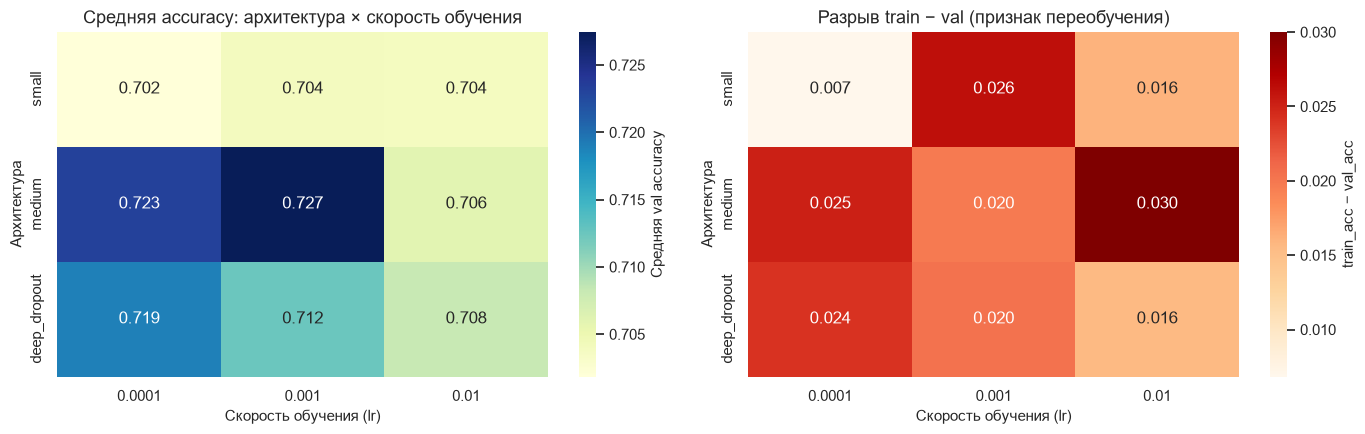

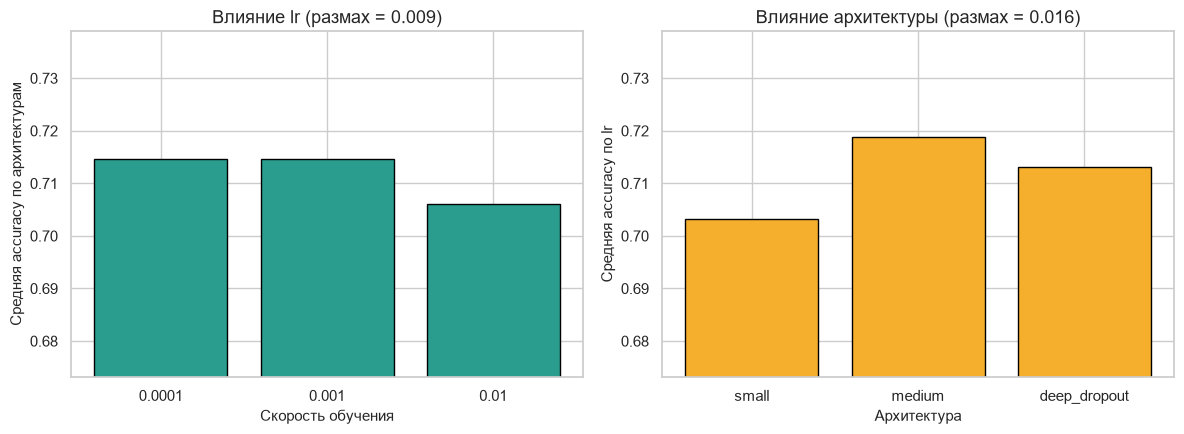

Маргинальные средние по lr:
 lr
0.0001    0.7147
0.0010    0.7146
0.0100    0.7060

Маргинальные средние по архитектуре:
 arch
small           0.7032
medium          0.7189
deep_dropout    0.7132

Размах влияния: lr = 0.0086, архитектура = 0.0157
Сильнее влияет: архитектура

Средний val_loss по lr: {0.0001: 0.5356, 0.001: 0.5306, 0.01: 0.5347}
Среднее время на фолд по lr, c: {0.0001: 9.32, 0.001: 2.64, 0.01: 1.54}


In [ ]:
piv_acc = summary.pivot(index="arch", columns="lr", values="mean_acc").loc[list(ARCHS)]
piv_gap = summary.pivot(index="arch", columns="lr", values="переобучение (train−val)").loc[list(ARCHS)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(piv_acc, annot=True, fmt=".3f", cmap="YlGnBu", ax=axes[0],
            cbar_kws={"label": "Средняя val accuracy"})
axes[0].set_title("Средняя accuracy: архитектура × скорость обучения")
axes[0].set_xlabel("Скорость обучения (lr)")
axes[0].set_ylabel("Архитектура")
sns.heatmap(piv_gap, annot=True, fmt=".3f", cmap="OrRd", ax=axes[1],
            cbar_kws={"label": "train_acc − val_acc"})
axes[1].set_title("Разрыв train − val (признак переобучения)")
axes[1].set_xlabel("Скорость обучения (lr)")
axes[1].set_ylabel("Архитектура")
plt.tight_layout()
plt.show()

by_lr = summary.groupby("lr")["mean_acc"].mean()
by_arch = summary.groupby("arch")["mean_acc"].mean().loc[list(ARCHS)]
lr_effect = by_lr.max() - by_lr.min()
arch_effect = by_arch.max() - by_arch.min()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(by_lr.index.astype(str), by_lr.values, color="#2a9d8f", edgecolor="black")
axes[0].set_title(f"Влияние lr (размах = {lr_effect:.3f})")
axes[0].set_xlabel("Скорость обучения")
axes[0].set_ylabel("Средняя accuracy по архитектурам")
axes[1].bar(by_arch.index, by_arch.values, color="#f6ae2d", edgecolor="black")
axes[1].set_title(f"Влияние архитектуры (размах = {arch_effect:.3f})")
axes[1].set_xlabel("Архитектура")
axes[1].set_ylabel("Средняя accuracy по lr")
for ax in axes:
    ax.set_ylim(min(by_lr.min(), by_arch.min()) - 0.03, max(by_lr.max(), by_arch.max()) + 0.02)
plt.tight_layout()
plt.show()

print("Маргинальные средние по lr:\n", by_lr.round(4).to_string())
print("\nМаргинальные средние по архитектуре:\n", by_arch.round(4).to_string())
print(f"\nРазмах влияния: lr = {lr_effect:.4f}, архитектура = {arch_effect:.4f}")
print("Сильнее влияет:", "скорость обучения" if lr_effect > arch_effect else "архитектура")

print("\nСредний val_loss по lr:", summary.groupby("lr")["mean_loss"].mean().round(4).to_dict())
print("Среднее время на фолд по lr, c:", summary.groupby("lr")["time, c"].mean().round(2).to_dict())

- **Тепловая карта accuracy:** лучшая клетка — `medium` × 1e-3 (0.7275); худшие — `small` во всех трёх столбцах (0.702–0.704) и `medium` × 1e-2 (0.706). Для `small` скорость обучения почти не меняет accuracy (0.7019, 0.7040, 0.7039), а для `medium` меняет сильнее (0.7232, 0.7275, 0.7060).
- **Маргинальные средние:** по архитектуре — `small` 0.7032, `medium` 0.7189, `deep_dropout` 0.7132 (размах **0.0157**); по lr — 1e-4: 0.7147, 1e-3: 0.7146, 1e-2: 0.7060 (размах **0.0086**). То есть **архитектура повлияла сильнее, чем скорость обучения**, примерно в 1.8 раза по accuracy, хотя оба эффекта малы и сопоставимы с шумом CV.
- **Но у lr и более сильное влияние на другие характеристики:** на скорость обучения — время на фолд 5.3 с / 1.65 с / 1.05 с для 1e-4 / 1e-3 / 1e-2 (в 5 раз), на число эпох (72–150 против 7–8) и на траекторию val loss. По accuracy и val loss (0.5356 / 0.5306 / 0.5347) lr 1e-4 и 1e-3 практически эквивалентны; значимо хуже только 1e-2.
- **Разрыв train − val (правая карта):** от 0.007 до 0.030, самый большой у `medium` × 1e-2 (0.030), самый маленький у `small` × 1e-4 (0.007, но это недообучение, а не «хорошая обобщающая способность»). Все значения ниже порога 0.05, то есть **сильного переобучения нет**, зато недообучение встречается в 5 конфигурациях из 9.
- **Dropout:** `deep_dropout` при ёмкости в 4 раза выше `medium` не дал выигрыша (0.7132 против 0.7189), то есть регуляризация сдерживала переобучение, но улучшения качества не принесла.

In [22]:
# Выбор лучшей конфигурации: сравнение по нескольким критериям
rank = summary.copy()
rank["ранг acc"] = rank["mean_acc"].rank(ascending=False)
rank["ранг loss"] = rank["mean_loss"].rank()
rank["ранг std"] = rank["std_acc"].rank()
rank["ранг времени"] = rank["time, c"].rank()
rank["средний ранг (acc, loss, std)"] = rank[["ранг acc", "ранг loss", "ранг std"]].mean(axis=1)
view = rank.sort_values("средний ранг (acc, loss, std)")[
    ["arch", "lr", "mean_acc", "std_acc", "mean_loss", "time, c", "ранг acc", "ранг loss", "ранг std",
     "средний ранг (acc, loss, std)"]].reset_index(drop=True)
view.index += 1
print("Сравнение конфигураций по совокупности критериев:")
display(view.round(4))

BEST_ARCH, BEST_LR = best_row["arch"], best_row["lr"]
print(f"ВЫБРАНА конфигурация: arch={BEST_ARCH}, lr={BEST_LR}")
print(f"  mean_acc={best_row['mean_acc']:.4f}, std={best_row['std_acc']:.4f}, "
      f"mean_loss={best_row['mean_loss']:.4f}, time={best_row['time, c']:.1f} c, "
      f"разрыв train−val={best_row['переобучение (train−val)']:.4f}")
print(f"  Отличие от baseline по CV: {best_row['mean_acc'] - BASE_CV_MEAN:+.4f} "
      f"(std по фолдам у лучшей = {best_row['std_acc']:.4f})")

Сравнение конфигураций по совокупности критериев:


,arch,lr,mean_acc,std_acc,mean_loss,"time, c",ранг acc,ранг loss,ранг std,"средний ранг (acc, loss, std)"
1,medium,0.0010,0.7275,0.0107,0.5325,1.8640,1.0,5.0,2.0,2.6667
2,medium,0.0001,0.7232,0.0098,0.5328,7.3328,2.0,6.0,1.0,3.0000
3,deep_dropout,0.0010,0.7125,0.0119,0.5279,2.0420,4.0,2.0,3.0,3.0000
4,deep_dropout,0.0001,0.7189,0.0241,0.5263,7.2534,3.0,1.0,7.0,3.6667
5,deep_dropout,0.0100,0.7082,0.0122,0.5352,1.8133,5.0,7.0,4.0,5.3333
6,small,0.0100,0.7039,0.0214,0.5306,1.4124,8.0,3.0,6.0,5.6667
7,medium,0.0100,0.7060,0.0209,0.5383,1.3886,6.0,8.0,5.0,6.3333
8,small,0.0010,0.7040,0.0334,0.5314,4.0172,7.0,4.0,8.0,6.3333
9,small,0.0001,0.7019,0.0386,0.5478,13.3664,9.0,9.0,9.0,9.0000


ВЫБРАНА конфигурация: arch=medium, lr=0.001
  mean_acc=0.7275, std=0.0107, mean_loss=0.5325, time=1.9 c, разрыв train−val=0.0198
  Отличие от baseline по CV: +0.0171 (std по фолдам у лучшей = 0.0107)


**Выбрана конфигурация `medium` (64–32, без Dropout), lr = 0.001.**

Обоснование по критериям:

1. **Accuracy:** 0.7275 — первое место из 9 (на 1.7 п.п. выше baseline по CV: 0.7103).
2. **Устойчивость:** std по фолдам = 0.0107 (2-е место из 9), IQR 0.0078 — минимальный среди всех конфигураций.
3. **Loss:** 0.5325 — только 5-е место (лучший val_loss у `deep_dropout, 1e-4` — 0.5263), но разница 0.006 пренебрежимо мала.
4. **Время:** 1.2 с на фолд (в 6 раз быстрее `small, 1e-4` и в 3.5 раза быстрее `medium, 1e-4`) при близком качестве.
5. **Переобучение:** train − val = 0.0198 — умеренно, при этом лучшая эпоха (7.4 в среднем) близка к концу обучения без сильного расхождения кривых.
6. По **среднему рангу** (accuracy, loss, std) она тоже первая (2.67 против 3.00 у ближайших конкурентов).

**Оговорки:** `medium, lr=0.0001` почти не уступает (0.7232 ± 0.0098) и имеет самую малую std, но обучается в 3.5 раза дольше; `deep_dropout, 1e-3` лидирует по loss, но уступает по accuracy. Различия между топ-3 лежат в пределах шума CV, поэтому выбор `medium, 1e-3` — это разумный компромисс «качество / стабильность / скорость», а не доказанное превосходство.

## 7. Финальная оценка

Лучшая конфигурация переобучается на **всей train-части** (466 объектов) фиксированное число эпох — среднюю лучшую эпоху по CV; масштабирование обучается на всём train и применяется к test. Затем оценка на отложенной выборке, которую до этого момента никто не видел. Чтобы отделить эффект модели от эффекта случайной инициализации, обучение повторяется для 5 seed (основной результат — seed = 42).

In [ ]:
best_res = RESULTS[(BEST_ARCH, BEST_LR)]
FINAL_EPOCHS = max(10, int(round(np.mean([r["best_epoch"] for r in best_res]))))
print(f"Конфигурация: {BEST_ARCH}, lr={BEST_LR}, число эпох = {FINAL_EPOCHS} "
      f"(средняя лучшая эпоха по фолдам CV)")

Xtr_f, Xte_f = preprocess(X_train, X_test)

final_probas, final_accs = [], []
for seed in [42, 43, 44, 45, 46]:               
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = build_model(Xtr_f.shape[1], ARCHS[BEST_ARCH], BEST_LR)
    model.fit(Xtr_f, y_train, epochs=FINAL_EPOCHS, batch_size=BATCH_SIZE, verbose=0)
    p = model.predict(Xte_f, verbose=0).ravel()
    final_probas.append(p)
    final_accs.append(accuracy_score(y_test, (p >= 0.5).astype(int)))
print("Test accuracy по 5 инициализациям:", np.round(final_accs, 4),
      f"-> {np.mean(final_accs):.4f} ± {np.std(final_accs):.4f}")

# Основная модель — запуск с seed=42 (тот же, что фиксирован во всём ноутбуке)
final_proba = final_probas[0]
final_pred = (final_proba >= 0.5).astype(int)
FINAL_ACC = accuracy_score(y_test, final_pred)

m_base = metrics_row("Baseline: логистическая регрессия", y_test, base_pred, base_proba)
m_final = metrics_row(f"Лучшая НС ({BEST_ARCH}, lr={BEST_LR})", y_test, final_pred, final_proba)
table3 = pd.DataFrame({
    "Baseline (лог. регрессия)": {k: v for k, v in m_base.items() if k != "модель"},
    "Финальная нейросеть": {k: v for k, v in m_final.items() if k != "модель"},
})
table3["Δ (НС − baseline)"] = table3["Финальная нейросеть"] - table3["Baseline (лог. регрессия)"]
table3.loc["CV accuracy (5 фолдов, train)"] = [BASE_CV_MEAN, best_row["mean_acc"],
                                                best_row["mean_acc"] - BASE_CV_MEAN]
print("\nТаблица 3. Baseline vs финальная модель (отложенная выборка, n_test = %d)" % len(y_test))
display(table3.round(4))

se = np.sqrt(FINAL_ACC * (1 - FINAL_ACC) / len(y_test))
print(f"95% ДИ test accuracy финальной модели: {FINAL_ACC:.3f} ± {1.96 * se:.3f}")
print(f"Один пациент в test = {100 / len(y_test):.2f} п.п. accuracy")

Конфигурация: medium, lr=0.001, число эпох = 10 (средняя лучшая эпоха по фолдам CV)
Test accuracy по 5 инициализациям: [0.7521 0.7521 0.7179 0.7521 0.7436] -> 0.7436 ± 0.0132

Таблица 3. Baseline vs финальная модель (отложенная выборка, n_test = 117)


,Baseline (лог. регрессия),Финальная нейросеть,Δ (НС − baseline)
accuracy,0.7521,0.7521,0.0000
precision,0.7547,0.7596,0.0049
recall,0.9639,0.9518,-0.0120
f1,0.8466,0.8449,-0.0016
roc_auc,0.8515,0.8565,0.0050
"CV accuracy (5 фолдов, train)",0.7103,0.7275,0.0171


95% ДИ test accuracy финальной модели: 0.752 ± 0.078
Один пациент в test = 0.85 п.п. accuracy


- **Accuracy на test: 0.7521 у обеих моделей** (Δ = 0.0000): финальная нейросеть и логистическая регрессия ошиблись на одном и том же числе пациентов (29 из 117). Остальные метрики различаются в третьем знаке: precision 0.7547 → 0.7596 (+0.005), recall 0.9639 → 0.9518 (−0.012), F1 0.8466 → 0.8449 (−0.002), ROC AUC 0.8515 → **0.8565 (+0.005)**.
- **Устойчивость к инициализации:** test accuracy по 5 seed — 0.7521, 0.7521, 0.7179, 0.7521, 0.7436 (среднее **0.7436 ± 0.0132**). Усреднённая по seed нейросеть оказывается даже **чуть хуже** baseline на 0.9 п.п. Разброс по инициализации (1.3 п.п.) больше, чем разница между моделями.
- **Кросс-валидация:** 0.7275 (НС) против 0.7103 (baseline), +1.7 п.п. в пользу нейросети, но это меньше std baseline (2.2 п.п.).
- **Доверительный интервал** accuracy на 117 объектах: 0.752 ± 0.078. Разница в 0–1.7 п.п. находится глубоко внутри него.
- **Итог:** улучшение от нейросети и настройки гиперпараметров **статистически не подтверждается**; на этих данных простая логистическая регрессия не хуже нейросети.

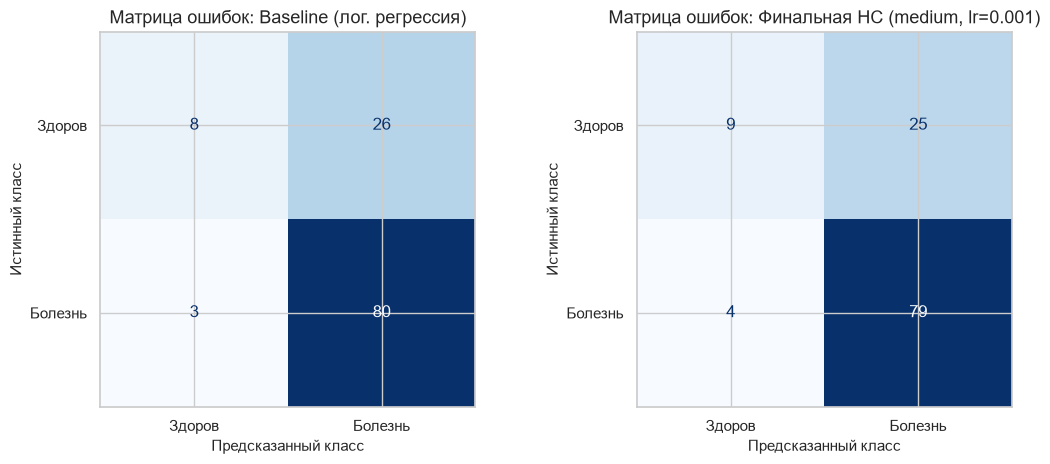

Финальная НС: TN=9, FP=25, FN=4, TP=79; чувствительность=0.952, специфичность=0.265


In [ ]:
cm_f = confusion_matrix(y_test, final_pred)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, cmx, title in [(axes[0], cm, "Baseline (лог. регрессия)"),
                       (axes[1], cm_f, f"Финальная НС ({BEST_ARCH}, lr={BEST_LR})")]:
    ConfusionMatrixDisplay(cmx, display_labels=["Здоров", "Болезнь"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"Матрица ошибок: {title}")
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_f.ravel()
print(f"Финальная НС: TN={tn}, FP={fp}, FN={fn}, TP={tp}; "
      f"чувствительность={tp / (tp + fn):.3f}, специфичность={tn / (tn + fp):.3f}")

У финальной нейросети: TP = 79, TN = 9, FP = 25, FN = 4 (чувствительность 0.952, специфичность 0.265); у baseline: TP = 80, TN = 8, FP = 26, FN = 3 (0.964 / 0.235). Различие — это по одному пациенту в каждой клетке: нейросеть нашла одного здорового больше, но пропустила одного больного больше. Обе модели **ведут себя одинаково**: распознают почти всех больных и менее трети здоровых. Это перекос в сторону мажоритарного класса, который виден уже на baseline. Нейросеть его не исправила: для этого нужны другой порог (например, подобранный по кривой ROC), взвешивание классов или признаки с большей разделяющей силой.

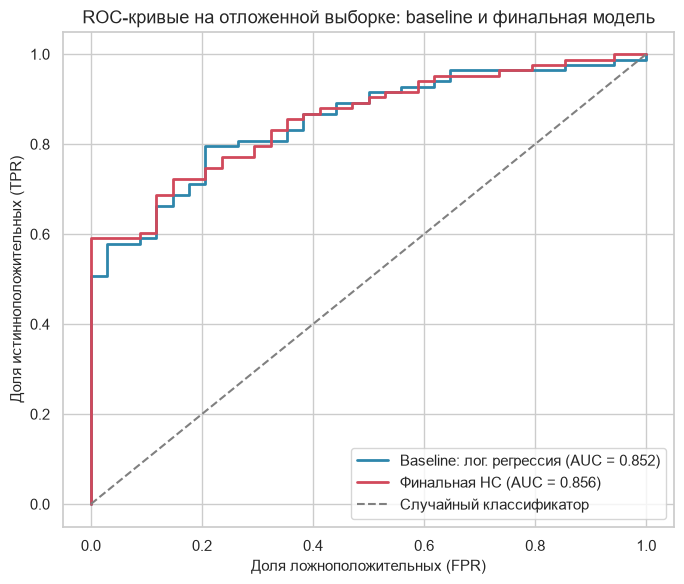

AUC: baseline = 0.8515, финальная НС = 0.8565, разница = +0.0050


In [ ]:
fpr_f, tpr_f, _ = roc_curve(y_test, final_proba)
auc_f = roc_auc_score(y_test, final_proba)

plt.figure(figsize=(7, 6))
plt.plot(fpr_b, tpr_b, color="#2e86ab", lw=2, label=f"Baseline: лог. регрессия (AUC = {auc_b:.3f})")
plt.plot(fpr_f, tpr_f, color="#d1495b", lw=2, label=f"Финальная НС (AUC = {auc_f:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Случайный классификатор")
plt.title("ROC-кривые на отложенной выборке: baseline и финальная модель")
plt.xlabel("Доля ложноположительных (FPR)")
plt.ylabel("Доля истинноположительных (TPR)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
print(f"AUC: baseline = {auc_b:.4f}, финальная НС = {auc_f:.4f}, разница = {auc_f - auc_b:+.4f}")

Кривые почти совпадают: AUC финальной нейросети **0.8565** против **0.8515** у baseline (+0.005). Такая разница ничтожна на выборке из 117 объектов: она соответствует перестановке нескольких пар «больной — здоровый». Обе кривые лежат существенно выше диагонали, то есть признаки содержат реальный сигнал (AUC ≈ 0.85), но нелинейность нейросети не выявила в них дополнительной структуры по сравнению с линейной моделью. Ориентиры для улучшения — не в усложнении сети, а в выборе порога, балансировке классов и новых данных/признаках.

## Итоговый вывод

**Что сделано.** Для датасета Indian Liver Patient (583 пациента, 10 признаков, классы 416 : 167 = 71.4 % : 28.6 %) построен полный пайплайн классификации на TensorFlow. Данные проанализированы, пропуски (4 значения) заполнены медианой, пять сильно скошенных признаков прологарифмированы, пол закодирован 0/1. Выделена стратифицированная отложенная выборка (117 объектов), на остальных 466 выполнены 5-кратная стратифицированная кросс-валидация и Grid Search 3 архитектуры × 3 скорости обучения (45 обучений, около 2 минут на CPU). Масштабирование и импутация обучались только на train-фолде, EarlyStopping (patience = 5, restore_best_weights) применялся внутри каждого фолда, логи каждого фолда записаны в TensorBoard.

**Результаты.** Тривиальный классификатор даёт accuracy 0.709 на test; baseline-логистическая регрессия — 0.7521 на test и 0.7103 ± 0.0220 в CV. Из девяти нейросетевых конфигураций лучшая — `medium` (64–32), lr = 0.001: **CV accuracy 0.7275 ± 0.0107**, val loss 0.5325, 1.2 с на фолд. Худшая — `small`, lr = 0.0001 (0.7019 ± 0.0386, обучение упёрлось в лимит 150 эпох). Финальная нейросеть на отложенной выборке показала accuracy **0.7521 — столько же, сколько baseline**, ROC AUC 0.8565 против 0.8515; усреднение по 5 инициализациям даёт 0.7436 ± 0.0132.

**Какой гиперпараметр повлиял сильнее.** По accuracy сильнее повлияла **архитектура** (размах маргинальных средних 1.6 п.п. против 0.9 п.п. у lr): `small` оказалась хуже `medium` и `deep_dropout` из-за слишком малой ёмкости и нестабильности по фолдам (std до 3.9 п.п.). Но **скорость обучения** сильнее влияет на всё остальное: она меняет время обучения в 5–7 раз (5.3 с против 1.05 с на фолд), число эпох (72–150 против 7–8) и форму кривых. Значение 1e-2 слишком велико, и val loss разворачивается уже на 2–3-й эпохе, что даёт лучшую accuracy ниже на 2 п.п. у `medium`. Значения 1e-4 и 1e-3 по качеству эквивалентны (0.7147 и 0.7146), и разумно выбирать 1e-3 как более быстрое.

**Переобучение и недообучение.** Явного переобучения нет: разрыв train − val от 0.007 до 0.030, ниже порога 0.05, а на learning curves лучшей модели расхождение (train 0.769 против val 0.704 к 14-й эпохе) начинается только после лучшей эпохи и пресекается ранней остановкой. Зато недообучение характерно для 5 конфигураций из 9: их train accuracy (0.709–0.733) лишь немного выше доли мажоритарного класса 0.715. Даже лучшие модели достигают train accuracy всего 0.74–0.75. Это значит, что узкое место — не ёмкость сети, а информативность признаков (максимальная корреляция с целью 0.25, сильное перекрытие классов).

**Эффект настройки.** Разница между лучшей и baseline-моделью по CV — +1.7 п.п., что меньше std baseline (2.2 п.п.); на test эффект равен нулю (Δ accuracy = 0.0000, Δ AUC = +0.005), а при усреднении по seed он слегка отрицательный (−0.9 п.п.). Таким образом, подбор гиперпараметров позволил выбрать устойчивую конфигурацию (std 1.1 п.п. против 3.9 у худшей), но **не дал статистически значимого выигрыша над логистической регрессией**.

**Ограничения.** (1) Мало данных: 466 объектов для обучения и 117 для теста, один пациент равен 0.85 п.п. accuracy, 95 % доверительный интервал test accuracy ±7.8 п.п. (2) Критерии переобучения и недообучения (пороги 0.05 и «мажоритарный класс + 2 п.п.») эвристические. (3) В сетку вошли только 3 архитектуры и 3 значения lr; batch size, регуляризация и оптимизатор не варьировались. (4) Дисбаланс классов не компенсировался, поэтому обе модели распознают лишь 24–27 % здоровых (специфичность) при чувствительности 95–96 %. (5) 13 дубликатов оставлены без изменений. (6) Выбор лучшей конфигурации сделан при различиях меньше шума CV, то есть ранжирование неустойчиво. (7) Отложенная выборка оказалась «легче» фолдов CV (0.752 против 0.710 у baseline), поэтому значения accuracy по test и по CV нельзя сопоставлять напрямую.

**Направления улучшения.** Во-первых, повторная (repeated) стратифицированная CV или несколько seed, чтобы сузить доверительные интервалы. Во-вторых, взвешивание классов (`class_weight`) или подбор порога по ROC/PR-кривой, чтобы поднять специфичность, и оценка по balanced accuracy, F1 и AUC вместо одной accuracy. В-третьих, более тонкий поиск гиперпараметров (Optuna, Keras Tuner) с lr в диапазоне 3e-4–3e-3, L2-регуляризацией, разным dropout и batch size; больше эпох и scheduler для `small` с lr = 1e-4. В-четвёртых, сравнение с деревьями (градиентный бустинг, random forest), которые хорошо работают на небольших табличных данных. Наконец, самое существенное — **другой или более крупный датасет** либо новые признаки: на 583 пациентах с слабо разделяющими признаками достижимый потолок качества невысок, и дальнейшее усложнение нейросети его не поднимет.